# 1. IMPORT LIBRARY

In [1]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from xgboost import XGBClassifier

# 2. LOAD DATASET

In [3]:
DATA_PATH = Path("../data/processed")

feature_A = pd.read_csv(DATA_PATH / "feature_A.csv")
feature_AB = pd.read_csv(DATA_PATH / "feature_AB.csv")

# 3. FEATURE A

feature & label

In [4]:
X_A = feature_A.drop(columns=["user_id", "label", "source_folder"], errors="ignore")
y_A = feature_A["label"]

encode label

In [5]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
y_A = encoder.fit_transform(y_A)

train test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_A,
    y_A,
    test_size=0.2,
    random_state=42,
    stratify=y_A
)

training

In [7]:
xgb_A = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

xgb_A.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


prediction

In [8]:
y_pred = xgb_A.predict(X_test)

evaluation

In [9]:
acc_A = accuracy_score(y_test, y_pred)
pre_A = precision_score(y_test, y_pred, average="macro")
rec_A = recall_score(y_test, y_pred, average="macro")
f1_A = f1_score(y_test, y_pred, average="macro")

print("Accuracy :", acc_A)
print("Precision:", pre_A)
print("Recall   :", rec_A)
print("F1 Score :", f1_A)

Accuracy : 0.988865692414753
Precision: 0.9830115455706379
Recall   : 0.9867776453458619
F1 Score : 0.9848769177642938


classif report

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

              precision    recall  f1-score   support

         bot       0.99      0.99      0.99      2179
       human       0.97      0.98      0.98       695

    accuracy                           0.99      2874
   macro avg       0.98      0.99      0.98      2874
weighted avg       0.99      0.99      0.99      2874



# 4. FEATURE A+B

pisahkan feature

In [11]:
X_AB = feature_AB.drop(columns=["user_id", "label", "source_folder"], errors="ignore")
y_AB = feature_AB["label"]
y_AB = encoder.transform(y_AB)

train test split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_AB,
    y_AB,
    test_size=0.2,
    random_state=42,
    stratify=y_AB
)


training

In [13]:
xgb_AB = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

xgb_AB.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


prediction

In [14]:
y_pred = xgb_AB.predict(X_test)

evaluation

In [15]:
acc_AB = accuracy_score(y_test, y_pred)
pre_AB = precision_score(y_test, y_pred, average="macro")
rec_AB = recall_score(y_test, y_pred, average="macro")
f1_AB = f1_score(y_test, y_pred, average="macro")


classif report

In [16]:
print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

              precision    recall  f1-score   support

         bot       1.00      0.99      0.99      2179
       human       0.97      0.99      0.98       695

    accuracy                           0.99      2874
   macro avg       0.98      0.99      0.99      2874
weighted avg       0.99      0.99      0.99      2874



confusion matrix

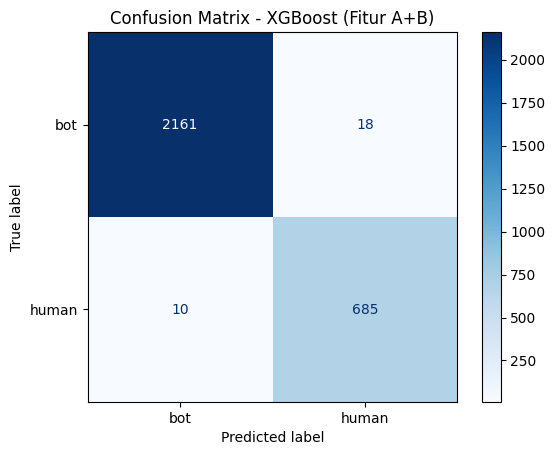

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - XGBoost (Fitur A+B)")
plt.savefig("../results/confusion_matrix_xgb_AB.png", dpi=150, bbox_inches="tight")
plt.show()

ROC Curve + AUC

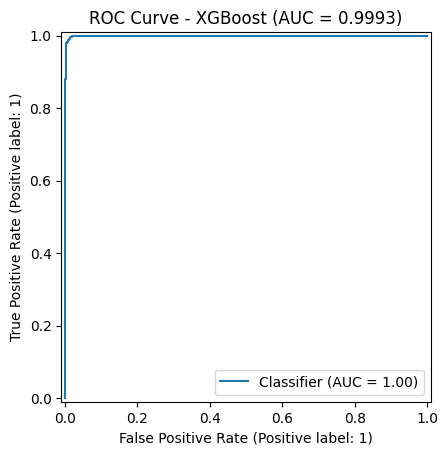

AUC Score: 0.9993429762844153


In [18]:
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay

y_proba = xgb_AB.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title(f"ROC Curve - XGBoost (AUC = {auc:.4f})")
plt.savefig("../results/roc_curve_xgb_AB.png", dpi=150, bbox_inches="tight")
plt.show()

print("AUC Score:", auc)

Loss curve

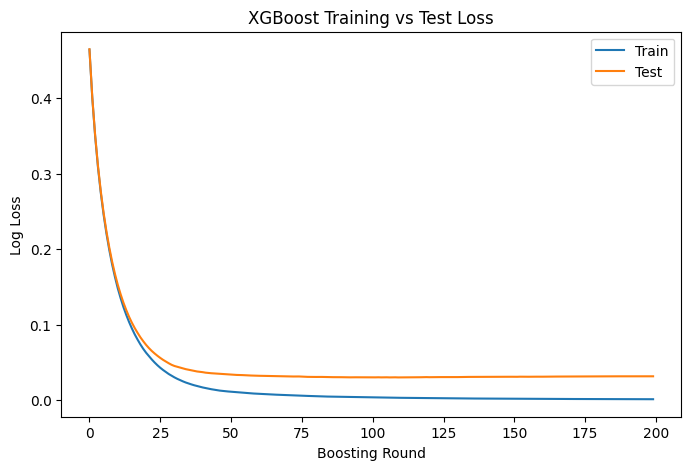

In [19]:
xgb_AB_eval = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

xgb_AB_eval.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

results_eval = xgb_AB_eval.evals_result()

plt.figure(figsize=(8,5))
plt.plot(results_eval["validation_0"]["logloss"], label="Train")
plt.plot(results_eval["validation_1"]["logloss"], label="Test")
plt.xlabel("Boosting Round")
plt.ylabel("Log Loss")
plt.title("XGBoost Training vs Test Loss")
plt.legend()
plt.savefig("../results/loss_curve_xgb_AB.png", dpi=150, bbox_inches="tight")
plt.show()

feature importance

In [20]:
importance = pd.DataFrame({
    "Feature": X_AB.columns,
    "Importance": xgb_AB.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)
importance.head(15)

,Feature,Importance
4,favourites_count,0.825704
11,favorites_per_day,0.049754
21,duplicate_content_score,0.014378
12,listed_ratio,0.013849
20,sync_hashtag_score,0.013186
13,tweet_count,0.008055
10,tweets_per_day,0.007344
9,follow_ratio,0.007047
14,avg_tweet_length,0.006959
17,avg_mention_count,0.006412


In [21]:
# coba Robustness check tanpa favourites_count

X_AB_noFav = X_AB.drop(
    columns=["favourites_count", "favorites_per_day"],
    errors="ignore"
)

X_train_nf, X_test_nf, y_train_nf, y_test_nf = train_test_split(
    X_AB_noFav,
    y_AB,
    test_size=0.2,
    random_state=42,
    stratify=y_AB
)

xgb_AB_noFav = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

xgb_AB_noFav.fit(X_train_nf, y_train_nf)
y_pred_nf = xgb_AB_noFav.predict(X_test_nf)

acc_nf = accuracy_score(y_test_nf, y_pred_nf)
pre_nf = precision_score(y_test_nf, y_pred_nf, average="macro")
rec_nf = recall_score(y_test_nf, y_pred_nf, average="macro")
f1_nf  = f1_score(y_test_nf, y_pred_nf, average="macro")

print("=== Tanpa favourites_count & favorites_per_day ===")
print("Accuracy :", acc_nf)
print("Precision:", pre_nf)
print("Recall   :", rec_nf)
print("F1 Score :", f1_nf)
print()
print(classification_report(
    y_test_nf, y_pred_nf, target_names=encoder.classes_
))

comparison_robust = pd.DataFrame({
    "Skenario": ["Dengan favourites_count", "Tanpa favourites_count"],
    "Accuracy": [acc_AB, acc_nf],
    "Precision": [pre_AB, pre_nf],
    "Recall": [rec_AB, rec_nf],
    "F1 Score": [f1_AB, f1_nf]
})
print(comparison_robust)

importance_nf = pd.DataFrame({
    "Feature": X_AB_noFav.columns,
    "Importance": xgb_AB_noFav.feature_importances_
})
importance_nf = importance_nf.sort_values(by="Importance", ascending=False)
print(importance_nf.head(15))

=== Tanpa favourites_count & favorites_per_day ===
Accuracy : 0.9902574808629089
Precision: 0.9844501338983549
Recall   : 0.9891653817836048
F1 Score : 0.9867801287948482

              precision    recall  f1-score   support

         bot       1.00      0.99      0.99      2179
       human       0.97      0.99      0.98       695

    accuracy                           0.99      2874
   macro avg       0.98      0.99      0.99      2874
weighted avg       0.99      0.99      0.99      2874

                  Skenario  Accuracy  Precision    Recall  F1 Score
0  Dengan favourites_count  0.990257   0.984895  0.988675  0.986767
1   Tanpa favourites_count  0.990257   0.984450  0.989165  0.986780
                    Feature  Importance
9            tweets_per_day    0.436525
19  duplicate_content_score    0.268151
10             listed_ratio    0.054502
18       sync_hashtag_score    0.034665
3              listed_count    0.026107
11              tweet_count    0.022848
6               g

cross validation

In [22]:
# (buat cek overfitting)
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_acc = cross_val_score(xgb_AB, X_AB, y_AB, cv=cv, scoring="accuracy")
scores_f1  = cross_val_score(xgb_AB, X_AB, y_AB, cv=cv, scoring="f1_macro")

print("Accuracy per fold :", scores_acc)
print("Accuracy mean/std :", scores_acc.mean(), scores_acc.std())
print()
print("F1 per fold        :", scores_f1)
print("F1 mean/std         :", scores_f1.mean(), scores_f1.std())

train_acc = xgb_AB.score(X_train, y_train)
test_acc  = xgb_AB.score(X_test, y_test)
print()
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Gap           : {train_acc - test_acc:.4f}")

Accuracy per fold : [0.99304106 0.99164927 0.98956159 0.98955795 0.98920989]
Accuracy mean/std : 0.9906039504410922 0.0014937358456579824

F1 per fold        : [0.99052966 0.98863559 0.98583585 0.98577903 0.9852834 ]
F1 mean/std         : 0.9872127067582307 0.0020347073036323144

Train Accuracy: 1.0000
Test Accuracy : 0.9903
Gap           : 0.0097


hyperparameter tuning

In [23]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        random_state=42,
        eval_metric="logloss"
    ),
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Params:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

xgb_AB_tuned = grid_search.best_estimator_
y_pred_tuned = xgb_AB_tuned.predict(X_test)

acc_tuned = accuracy_score(y_test, y_pred_tuned)
pre_tuned = precision_score(y_test, y_pred_tuned, average="macro")
rec_tuned = recall_score(y_test, y_pred_tuned, average="macro")
f1_tuned  = f1_score(y_test, y_pred_tuned, average="macro")

print("\n=== Model Setelah Tuning (Test Set) ===")
print("Accuracy :", acc_tuned)
print("Precision:", pre_tuned)
print("Recall   :", rec_tuned)
print("F1 Score :", f1_tuned)

comparison_tuning = pd.DataFrame({
    "Skenario": ["Default params", "Tuned params"],
    "Accuracy": [acc_AB, acc_tuned],
    "Precision": [pre_AB, pre_tuned],
    "Recall": [rec_AB, rec_tuned],
    "F1 Score": [f1_AB, f1_tuned]
})
print(comparison_tuning)

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Best Params: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.8}
Best CV F1 Score: 0.9878026121150546

=== Model Setelah Tuning (Test Set) ===
Accuracy : 0.9909533750869868
Precision: 0.9858361840712928
Recall   : 0.9896243078965006
F1 Score : 0.9877124956834887
         Skenario  Accuracy  Precision    Recall  F1 Score
0  Default params  0.990257   0.984895  0.988675  0.986767
1    Tuned params  0.990953   0.985836  0.989624  0.987712


# 5. RESULT

In [24]:
results = pd.DataFrame({
    "Feature": ["A", "A+B"],
    "Accuracy": [acc_A, acc_AB],
    "Precision": [pre_A, pre_AB],
    "Recall": [rec_A, rec_AB],
    "F1 Score": [f1_A, f1_AB]
})

results

,Feature,Accuracy,Precision,Recall,F1 Score
0,A,0.988866,0.983012,0.986778,0.984877
1,A+B,0.990257,0.984895,0.988675,0.986767


In [25]:
import joblib

MODEL_PATH = Path("../models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(xgb_A, MODEL_PATH / "xgb_feature_A.pkl")
joblib.dump(xgb_AB, MODEL_PATH / "xgb_feature_AB.pkl")
joblib.dump(encoder, MODEL_PATH / "label_encoder.pkl")

['..\\models\\label_encoder.pkl']

In [26]:
RESULT_PATH = Path("../results")
RESULT_PATH.mkdir(parents=True, exist_ok=True)
results.to_csv(RESULT_PATH / "xgboost_results.csv", index=False)